### Generate Embeddings Usign ESM-2 model 
### N and C window extract specific residues and Generate Embedding using ESM-2 model

In [ ]:
from pathlib import Path

def read_fasta(input_fasta):
    """Reads a single-line or multi-line FASTA file into a list of (header, sequence) tuples."""
    input_path = Path(input_fasta)
    if not input_path.exists():
        raise FileNotFoundError(f"Input file not found: '{input_path.resolve()}'")

    records = []
    header = None
    seq_chunks = []

    with open(input_path, "r", encoding="utf-8") as f:
        for line in f:
            line = line.strip()
            if not line:
                continue
            if line.startswith(">"):
                if header is not None:
                    records.append((header, "".join(seq_chunks)))
                header = line
                seq_chunks = []
            else:
                seq_chunks.append(line)
        if header is not None:
            records.append((header, "".join(seq_chunks)))

    return records


def generate_all_windows(input_fasta, output_dir, window_configs, allow_overlap=True):
    """
    Reads `input_fasta` from any directory and saves truncated FASTA files
    into `output_dir` (creates `output_dir` automatically if missing).
    """
    records = read_fasta(input_fasta)
    
    # Create output directory if it does not exist
    out_folder = Path(output_dir)
    out_folder.mkdir(parents=True, exist_ok=True)

    print(f"Input File : {Path(input_fasta).resolve()}")
    print(f"Output Dir : {out_folder.resolve()}")
    print(f"Sequences  : {len(records):,}\n")
    print(f"{'Condition':<12} | {'Saved File':<22} | {'Target Len':<10} | {'Short Seqs (<Target)':<20}")
    print("-" * 75)

    for n_len, c_len, filename in window_configs:
        target_len = n_len + c_len
        short_count = 0
        out_path = out_folder / filename  # Combines output directory + filename safely

        with open(out_path, "w", encoding="utf-8") as out:
            for hdr, seq in records:
                if len(seq) < target_len:
                    short_count += 1
                    if allow_overlap:
                        n_term = seq[:n_len]
                        c_term = seq[-c_len:] if c_len > 0 else ""
                        truncated_seq = n_term + c_term
                    else:
                        truncated_seq = seq
                else:
                    n_term = seq[:n_len]
                    c_term = seq[-c_len:] if c_len > 0 else ""
                    truncated_seq = n_term + c_term

                out.write(f"{hdr}\n{truncated_seq}\n")

        cond_label = f"{n_len}/{c_len}"
        print(f"{cond_label:<12} | {filename:<22} | {target_len:<10} | {short_count:<20,}")

    print("\nDone! All files saved in:", out_folder.resolve())


# ==========================================
# SET YOUR INPUT AND OUTPUT PATHS HERE
# ==========================================
# Tip: Always use r"..." on Windows so backslashes (\) don't cause errors
INPUT_FASTA = r"C:\Users\sumit\OneDrive\Documenten\Thesis\comp-ss\Results\sumit_secretion_prediction\phase0_dataset_prep\Train_Test\train.fasta"       # <-- Change to your input file path
OUTPUT_DIR  = r"C:\Users\sumit\OneDrive\Documenten\Thesis\comp-ss\Results\sumit_secretion_prediction\phase1_feature_engineering\features\N_C_window"         # <-- Change to your desired output folder

WINDOW_CONDITIONS = [
    (30, 30, "N_C_30.fasta"),
    (40, 40, "N_C_40.fasta"),
    (50, 50, "N_C_50.fasta"),
    (30, 50, "N_30_C_50.fasta"),
]

# Run the pipeline
generate_all_windows(
    input_fasta=INPUT_FASTA,
    output_dir=OUTPUT_DIR,
    window_configs=WINDOW_CONDITIONS,
    allow_overlap=True
)

In [3]:
pip install torch

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [5]:
pip install transformers


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [9]:
pip install pandas

   ---------------------------------------- 0.0/10.9 MB ? eta -:--:--
   -------- ------------------------------- 2.4/10.9 MB 12.7 MB/s eta 0:00:01
   ----------------- ---------------------- 4.7/10.9 MB 12.8 MB/s eta 0:00:01
   -------------------------- ------------- 7.1/10.9 MB 12.8 MB/s eta 0:00:01
   ----------------------------------- ---- 9.7/10.9 MB 11.9 MB/s eta 0:00:01
   ---------------------------------------- 10.9/10.9 MB 10.7 MB/s  0:00:01
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [75]:
import numpy as np, pandas as pd, torch
from transformers import AutoTokenizer, AutoModel

MODEL = "facebook/esm2_t6_8M_UR50D"
FASTA = "C:/Users/sumit/OneDrive/Documenten/Thesis/comp-ss/Results/sumit_secretion_prediction/phase0_dataset_prep/Train_Test/test.fasta"                      # the ORIGINAL full-length test sequences
OUT   = "C:/Users/sumit/OneDrive/Documenten/Thesis/comp-ss/Results/sumit_secretion_prediction/phase1_feature_engineering/features/N_C_windowN_C_50_esm2_test.csv"
WN, WC = 50, 50

# 1. load model
tok   = AutoTokenizer.from_pretrained(MODEL)
model = AutoModel.from_pretrained(MODEL).eval()
DIM   = model.config.hidden_size

# 2. read the fasta
ids, seqs, name, parts = [], [], None, []
for line in open(FASTA, encoding="utf-8"):
    line = line.strip()
    if not line:
        continue
    if line.startswith(">"):
        if name is not None:
            seqs.append("".join(parts))
        name = line[1:].split()[0]
        ids.append(name); parts = []
    else:
        parts.append(line)
if name is not None:
    seqs.append("".join(parts))

lens = np.array([len(s) for s in seqs])
print(f"{len(seqs)} sequences, length {lens.min()}-{lens.max()}")
assert lens.min() >= max(WN, WC), f"a sequence is shorter than {max(WN,WC)} residues"
print(f"overlapping (len < {WN+WC}): {(lens < WN+WC).sum()} ({100*(lens<WN+WC).mean():.2f}%)")

# 3. cut the windows
windows = [s[:WN] + s[-WC:] for s in seqs]
assert len({len(w) for w in windows}) == 1 == len({WN+WC})
print(f"windows: {len(windows)} x {WN+WC} residues (uniform -> no padding)")

# 4. embed
out = []
for i in range(0, len(windows), 32):
    b = tok(windows[i:i+32], return_tensors="pt")
    with torch.no_grad():
        h = model(**b).last_hidden_state          # (B, 102, DIM)
    out.append(h[:, 1:-1, :].mean(1))             # strip cls/eos -> (B, DIM)
emb = torch.cat(out).numpy().astype(np.float32)

assert emb.shape == (len(ids), DIM)
assert np.isfinite(emb).all()
print(f"embeddings: {emb.shape}")

# 5. save, same format as the train file
df = pd.DataFrame(emb, columns=[f"esm_{i}" for i in range(DIM)])
df.insert(0, "protein_id", ids)
df.to_csv(OUT, index=False)
print(f"saved {OUT}  rows {len(df)}  cols {df.shape[1]}")

Loading weights: 100%|██████████| 102/102 [00:00<00:00, 1136.86it/s]
[transformers] EsmModel LOAD REPORT from: facebook/esm2_t6_8M_UR50D
Key                       | Status     | 
--------------------------+------------+-
lm_head.bias              | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
pooler.dense.bias         | MISSING    | 
pooler.dense.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


744 sequences, length 66-8682
overlapping (len < 100): 13 (1.75%)
windows: 744 x 100 residues (uniform -> no padding)
embeddings: (744, 320)
saved C:/Users/sumit/OneDrive/Documenten/Thesis/comp-ss/Results/sumit_secretion_prediction/phase1_feature_engineering/features/N_C_windowN_C_50_esm2_test.csv  rows 744  cols 321


In [62]:
import numpy as np,  torch
import pandas as pd
from transformers import AutoTokenizer, AutoModel

MODEL = "facebook/esm2_t6_8M_UR50D"
#FASTA = "C:/Users/sumit/OneDrive/Documenten/Thesis/comp-ss/Results/sumit_secretion_prediction/phase1_feature_engineering/features/N_C_window/N_C_30.fasta"
#OUT   = "C:/Users/sumit/OneDrive/Documenten/Thesis/comp-ss/Results/sumit_secretion_prediction/phase1_feature_engineering/features/N_C_window/N_C_30_esm2.csv"
#FASTA = "C:/Users/sumit/OneDrive/Documenten/Thesis/comp-ss/Results/sumit_secretion_prediction/phase1_feature_engineering/features/N_C_window/N_C_40.fasta"
#OUT   = "C:/Users/sumit/OneDrive/Documenten/Thesis/comp-ss/Results/sumit_secretion_prediction/phase1_feature_engineering/features/N_C_window/N_C_40_esm2.csv"
#FASTA = "C:/Users/sumit/OneDrive/Documenten/Thesis/comp-ss/Results/sumit_secretion_prediction/phase1_feature_engineering/features/N_C_window/N_C_50.fasta"
#OUT   = "C:/Users/sumit/OneDrive/Documenten/Thesis/comp-ss/Results/sumit_secretion_prediction/phase1_feature_engineering/features/N_C_window/N_C_50_esm2.csv"
#FASTA = "C:/Users/sumit/OneDrive/Documenten/Thesis/comp-ss/Results/sumit_secretion_prediction/phase1_feature_engineering/features/N_C_window/N_30_C_50.fasta"
#OUT   = "C:/Users/sumit/OneDrive/Documenten/Thesis/comp-ss/Results/sumit_secretion_prediction/phase1_feature_engineering/features/N_C_window/N_30_C_50_esm2.csv"
FASTA = "C:/Users/sumit/OneDrive/Documenten/Thesis/comp-ss/Results/sumit_secretion_prediction/phase1_feature_engineering/features/N_C_window/N_C_60.fasta"
OUT   = "C:/Users/sumit/OneDrive/Documenten/Thesis/comp-ss/Results/sumit_secretion_prediction/phase1_feature_engineering/features/N_C_window/N_C_60_esm2.csv"

# 1. load model
tok   = AutoTokenizer.from_pretrained(MODEL)
model = AutoModel.from_pretrained(MODEL).eval()

# 2. read the fasta (one line per sequence, as your generator writes it)
ids, seqs = [], []
for line in open(FASTA):
    line = line.strip()
    if line.startswith(">"):
        ids.append(line[1:].split()[0])
    elif line:
        seqs.append(line)

print(f"{len(seqs)} sequences, {len(seqs[0])} residues each")
assert len({len(s) for s in seqs}) == 1, "lengths not uniform"

# 3. embed in batches
out = []
for i in range(0, len(seqs), 32):
    batch = tok(seqs[i:i+32], return_tensors="pt")
    with torch.no_grad():
        h = model(**batch).last_hidden_state     # (B, 62, 320)
    out.append(h[:, 1:-1, :].mean(1))            # (B, 320)

emb = torch.cat(out).numpy()

# 4. save as csv: protein_id + one column per embedding dimension
df = pd.DataFrame(emb, columns=[f"esm_{i}" for i in range(emb.shape[1])])
df.insert(0, "protein_id", ids)
df.to_csv(OUT, index=False)

print(f"saved {OUT}  rows {len(df)}  cols {df.shape[1]} (1 id + {emb.shape[1]} dims)")

Loading weights: 100%|██████████| 102/102 [00:00<00:00, 6213.24it/s]
[transformers] EsmModel LOAD REPORT from: facebook/esm2_t6_8M_UR50D
Key                       | Status     | 
--------------------------+------------+-
lm_head.bias              | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
pooler.dense.bias         | MISSING    | 
pooler.dense.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


2967 sequences, 120 residues each
saved C:/Users/sumit/OneDrive/Documenten/Thesis/comp-ss/Results/sumit_secretion_prediction/phase1_feature_engineering/features/N_C_window/N_C_60_esm2.csv  rows 2967  cols 321 (1 id + 320 dims)


### Train SVC model on each Window condition 
### N_window :30 and C_window: 30

### Baseline of each class predication using DummyClassifier()

In [39]:
import numpy as np, pandas as pd
df_30= pd.read_csv("C:/Users/sumit/OneDrive/Documenten/Thesis/comp-ss/Results/sumit_secretion_prediction/phase1_feature_engineering/features/N_C_window/N_C_30_esm2.csv")    
x_30=df_30.drop(columns=["protein_id"]).to_numpy(dtype=np.float32)
label_30=df_30["protein_id"].to_numpy()
y_30=np.array([i.rsplit("-",1)[0] for  i in  label_30])

print("X", x_30.shape, x_30.dtype)
print("y", y_30.shape)
print(pd.Series(y_30).value_counts())
assert len(x_30) == len(y_30)
print(label_30[0], "->", y_30[0])

X (2967, 320) float32
y (2967,)
Non-secreted    1306
T4SS             438
T3SS             356
Sec              355
T6SS             218
T1SS             114
Tat               87
T2SS              62
T5SS              31
Name: count, dtype: int64
Non-secreted-1500 -> Non-secreted


In [23]:
# Generate 5-fold CV
import pickle
from sklearn.model_selection import StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [27]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

pipe = make_pipeline(
    StandardScaler(),
    SVC(kernel="rbf", C=1.0, gamma="scale", class_weight="balanced", random_state=42)
)
print(pipe)

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('svc', SVC(class_weight='balanced', random_state=42))])


In [40]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict
pred_30 = cross_val_predict(pipe, x_30, y_30, cv=cv)

print(pred_30.shape)
print(pred_30[:10])

(2967,)
['Non-secreted' 'Non-secreted' 'T4SS' 'T6SS' 'Non-secreted' 'Non-secreted'
 'Non-secreted' 'Non-secreted' 'T6SS' 'T6SS']


In [41]:
from sklearn.metrics import classification_report
from sklearn.metrics import f1_score

print(classification_report(y_30, pred_30, digits=3))
print("macro-F1:", round(f1_score(y_30, pred_30, average="macro"), 4))

              precision    recall  f1-score   support

Non-secreted      0.786     0.592     0.675      1306
         Sec      0.706     0.777     0.740       355
        T1SS      0.587     0.623     0.604       114
        T2SS      0.222     0.355     0.273        62
        T3SS      0.534     0.551     0.542       356
        T4SS      0.481     0.594     0.531       438
        T5SS      0.781     0.806     0.794        31
        T6SS      0.334     0.541     0.413       218
         Tat      0.911     0.828     0.867        87

    accuracy                          0.611      2967
   macro avg      0.594     0.630     0.604      2967
weighted avg      0.652     0.611     0.622      2967

macro-F1: 0.6045


### N_window :40  and  C_window:40

In [42]:
import numpy as np, pandas as pd
df_40= pd.read_csv("C:/Users/sumit/OneDrive/Documenten/Thesis/comp-ss/Results/sumit_secretion_prediction/phase1_feature_engineering/features/N_C_window/N_C_40_esm2.csv")    
x_40=df_40.drop(columns=["protein_id"]).to_numpy(dtype=np.float32)
label_40=df_40["protein_id"].to_numpy()
y_40=np.array([i.rsplit("-",1)[0] for  i in  label_40])

print("X", x_40.shape, x_40.dtype)
print("y", y_40.shape)
print(pd.Series(y_40).value_counts())
assert len(x_40) == len(y_40)
print(label_40[0], "->", y_40[0])

X (2967, 320) float32
y (2967,)
Non-secreted    1306
T4SS             438
T3SS             356
Sec              355
T6SS             218
T1SS             114
Tat               87
T2SS              62
T5SS              31
Name: count, dtype: int64
Non-secreted-1500 -> Non-secreted


In [45]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict
pred_40= cross_val_predict(pipe, x_40, y_40, cv=cv)

print(pred_40.shape)
print(pred_40[:10])

(2967,)
['T4SS' 'T4SS' 'T4SS' 'T4SS' 'Non-secreted' 'Non-secreted' 'Non-secreted'
 'Non-secreted' 'Non-secreted' 'Non-secreted']


In [46]:
from sklearn.metrics import classification_report
from sklearn.metrics import f1_score

print(classification_report(y_40, pred_40, digits=3))
print("macro-F1:", round(f1_score(y_40, pred_40, average="macro"), 4))

              precision    recall  f1-score   support

Non-secreted      0.820     0.639     0.719      1306
         Sec      0.716     0.839     0.773       355
        T1SS      0.779     0.711     0.743       114
        T2SS      0.257     0.435     0.323        62
        T3SS      0.637     0.601     0.618       356
        T4SS      0.520     0.646     0.576       438
        T5SS      0.765     0.839     0.800        31
        T6SS      0.406     0.596     0.483       218
         Tat      0.911     0.943     0.927        87

    accuracy                          0.666      2967
   macro avg      0.646     0.694     0.663      2967
weighted avg      0.700     0.666     0.674      2967

macro-F1: 0.6625


### N_window:50 and C_window :50


In [50]:
import numpy as np, pandas as pd
df_50= pd.read_csv("C:/Users/sumit/OneDrive/Documenten/Thesis/comp-ss/Results/sumit_secretion_prediction/phase1_feature_engineering/features/N_C_window/N_C_50_esm2.csv")    
x_50=df_50.drop(columns=["protein_id"]).to_numpy(dtype=np.float32)
label_50=df_50["protein_id"].to_numpy()
y_50=np.array([i.rsplit("-",1)[0] for  i in  label_50])

print("X", x_50.shape, x_50.dtype)
print("y", y_50.shape)
print(pd.Series(y_50).value_counts())
assert len(x_50) == len(y_50)
print(label_50[0], "->", y_50[0])

X (2967, 320) float32
y (2967,)
Non-secreted    1306
T4SS             438
T3SS             356
Sec              355
T6SS             218
T1SS             114
Tat               87
T2SS              62
T5SS              31
Name: count, dtype: int64
Non-secreted-1500 -> Non-secreted


In [51]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict
pred_50= cross_val_predict(pipe, x_50, y_50, cv=cv)

print(pred_50.shape)
print(pred_50[:10])

(2967,)
['T4SS' 'Non-secreted' 'Non-secreted' 'T4SS' 'Non-secreted' 'Non-secreted'
 'Non-secreted' 'Non-secreted' 'Non-secreted' 'Non-secreted']


In [52]:
from sklearn.metrics import classification_report
from sklearn.metrics import f1_score

print(classification_report(y_50, pred_50, digits=3))
print("macro-F1:", round(f1_score(y_50, pred_50, average="macro"), 4))

              precision    recall  f1-score   support

Non-secreted      0.848     0.684     0.757      1306
         Sec      0.727     0.839     0.779       355
        T1SS      0.851     0.754     0.800       114
        T2SS      0.258     0.500     0.341        62
        T3SS      0.657     0.646     0.652       356
        T4SS      0.557     0.662     0.605       438
        T5SS      0.853     0.935     0.892        31
        T6SS      0.477     0.624     0.541       218
         Tat      0.914     0.977     0.944        87

    accuracy                          0.700      2967
   macro avg      0.683     0.736     0.701      2967
weighted avg      0.730     0.700     0.709      2967

macro-F1: 0.7012


### N_window:30 and C_window:50

In [55]:
import numpy as np, pandas as pd
df_30_50= pd.read_csv("C:/Users/sumit/OneDrive/Documenten/Thesis/comp-ss/Results/sumit_secretion_prediction/phase1_feature_engineering/features/N_C_window/N_30_C_50_esm2.csv")    
x_30_50=df_30_50.drop(columns=["protein_id"]).to_numpy(dtype=np.float32)
label_30_50=df_30_50["protein_id"].to_numpy()
y_30_50=np.array([i.rsplit("-",1)[0] for  i in  label_30_50])

print("X", x_30_50.shape, x_30_50.dtype)
print("y", y_30_50.shape)
print(pd.Series(y_30_50).value_counts())
assert len(x_30_50) == len(y_30_50)
print(label_30_50[0], "->", y_30_50[0])

X (2967, 320) float32
y (2967,)
Non-secreted    1306
T4SS             438
T3SS             356
Sec              355
T6SS             218
T1SS             114
Tat               87
T2SS              62
T5SS              31
Name: count, dtype: int64
Non-secreted-1500 -> Non-secreted


In [56]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict
pred_30_50= cross_val_predict(pipe, x_30_50, y_30_50, cv=cv)

print(pred_30_50.shape)
print(pred_30_50[:10])

(2967,)
['Non-secreted' 'Non-secreted' 'T6SS' 'T4SS' 'Non-secreted' 'Non-secreted'
 'Non-secreted' 'Non-secreted' 'Non-secreted' 'Non-secreted']


In [57]:
from sklearn.metrics import classification_report
from sklearn.metrics import f1_score

print(classification_report(y_30_50, pred_30_50, digits=3))
print("macro-F1:", round(f1_score(y_30_50, pred_30_50, average="macro"), 4))

              precision    recall  f1-score   support

Non-secreted      0.810     0.651     0.722      1306
         Sec      0.730     0.814     0.770       355
        T1SS      0.798     0.693     0.742       114
        T2SS      0.301     0.500     0.376        62
        T3SS      0.587     0.598     0.592       356
        T4SS      0.540     0.662     0.595       438
        T5SS      0.800     0.903     0.848        31
        T6SS      0.397     0.560     0.465       218
         Tat      0.910     0.816     0.861        87

    accuracy                          0.665      2967
   macro avg      0.653     0.689     0.663      2967
weighted avg      0.695     0.665     0.673      2967

macro-F1: 0.6634


### N_window:60 and C_window_60

In [63]:
import numpy as np, pandas as pd
df_60= pd.read_csv("C:/Users/sumit/OneDrive/Documenten/Thesis/comp-ss/Results/sumit_secretion_prediction/phase1_feature_engineering/features/N_C_window/N_C_60_esm2.csv")    
x_60=df_60.drop(columns=["protein_id"]).to_numpy(dtype=np.float32)
label_60=df_60["protein_id"].to_numpy()
y_60=np.array([i.rsplit("-",1)[0] for  i in  label_60])

print("X", x_60.shape, x_60.dtype)
print("y", y_60.shape)
print(pd.Series(y_60).value_counts())
assert len(x_60) == len(y_60)
print(label_60[0], "->", y_60[0])

X (2967, 320) float32
y (2967,)
Non-secreted    1306
T4SS             438
T3SS             356
Sec              355
T6SS             218
T1SS             114
Tat               87
T2SS              62
T5SS              31
Name: count, dtype: int64
Non-secreted-1500 -> Non-secreted


In [64]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict
pred_60= cross_val_predict(pipe, x_60, y_60, cv=cv)

print(pred_60.shape)
print(pred_60[:10])

(2967,)
['T4SS' 'T6SS' 'T6SS' 'Non-secreted' 'Non-secreted' 'Non-secreted'
 'Non-secreted' 'Non-secreted' 'T6SS' 'Non-secreted']


In [65]:
from sklearn.metrics import classification_report
from sklearn.metrics import f1_score

print(classification_report(y_60, pred_60, digits=3))
print("macro-F1:", round(f1_score(y_60, pred_60, average="macro"), 4))

              precision    recall  f1-score   support

Non-secreted      0.845     0.699     0.765      1306
         Sec      0.730     0.828     0.776       355
        T1SS      0.827     0.754     0.789       114
        T2SS      0.302     0.565     0.393        62
        T3SS      0.680     0.610     0.643       356
        T4SS      0.556     0.669     0.607       438
        T5SS      0.778     0.903     0.836        31
        T6SS      0.497     0.661     0.567       218
         Tat      0.912     0.954     0.933        87

    accuracy                          0.705      2967
   macro avg      0.681     0.738     0.701      2967
weighted avg      0.732     0.705     0.713      2967

macro-F1: 0.7009


In [66]:
import pandas as pd

FASTA = "C:/Users/sumit/OneDrive/Documenten/Thesis/comp-ss/Results/sumit_secretion_prediction/phase0_dataset_prep/Train_Test/train.fasta"

# read the ORIGINAL full-length sequences
recs, name, parts = [], None, []
for line in open(FASTA, encoding="utf-8"):
    line = line.strip()
    if not line:
        continue
    if line.startswith(">"):
        if name is not None:
            recs.append((name, "".join(parts)))
        name, parts = line[1:].split()[0], []
    else:
        parts.append(line)
if name is not None:
    recs.append((name, "".join(parts)))

df = pd.DataFrame({"id": [i for i, _ in recs],
                   "length": [len(s) for _, s in recs]})
df["label"] = df.id.str.rsplit("-", n=1).str[0]
total = df.label.value_counts()

print(f"{len(df)} sequences, min length {df.length.min()}\n")

for cond, (wN, wC) in {"W1": (30,30), "W2": (40,40), "W3": (50,50), "W4": (60,60)}.items():
    need = wN + wC
    hit = df[df.length < need]
    print(f"{cond}  N={wN} C={wC}  needs {need}:  {len(hit)} of {len(df)} overlap ({100*len(hit)/len(df):.1f}%)")
    if len(hit):
        by = hit.label.value_counts()
        for c in by.index:
            print(f"     {c:<14} {by[c]:4d} of {total[c]:4d}   ({100*by[c]/total[c]:5.1f}% of class)")
        print(f"     duplicated residues: median {int((need-hit.length).median())}, max {int((need-hit.length).max())}")
    print()

2967 sequences, min length 62

W1  N=30 C=30  needs 60:  0 of 2967 overlap (0.0%)

W2  N=40 C=40  needs 80:  18 of 2967 overlap (0.6%)
     T1SS              5 of  114   (  4.4% of class)
     T4SS              5 of  438   (  1.1% of class)
     Non-secreted      4 of 1306   (  0.3% of class)
     T3SS              2 of  356   (  0.6% of class)
     Sec               1 of  355   (  0.3% of class)
     T6SS              1 of  218   (  0.5% of class)
     duplicated residues: median 8, max 18

W3  N=50 C=50  needs 100:  57 of 2967 overlap (1.9%)
     Non-secreted     26 of 1306   (  2.0% of class)
     T4SS             10 of  438   (  2.3% of class)
     T1SS              8 of  114   (  7.0% of class)
     Sec               7 of  355   (  2.0% of class)
     T3SS              3 of  356   (  0.8% of class)
     T6SS              3 of  218   (  1.4% of class)
     duplicated residues: median 10, max 38

W4  N=60 C=60  needs 120:  152 of 2967 overlap (5.1%)
     Non-secreted     80 of 1306 

In [61]:
import pandas as pd

input_fasta = "C:/Users/sumit/OneDrive/Documenten/Thesis/comp-ss/Results/sumit_secretion_prediction/phase0_dataset_prep/Train_Test/train.fasta"
output_fasta = "C:/Users/sumit/OneDrive/Documenten/Thesis/comp-ss/Results/sumit_secretion_prediction/phase1_feature_engineering/features/N_C_window/N_C_60.fasta"
N_WIN = 60
C_WIN = 60

records = []
with open(input_fasta, "r") as f:
    header = None
    seq_chunks = []
    for line in f:
        line = line.strip()
        if not line:
            continue
        if line.startswith(">"):
            if header is not None:
                records.append((header, "".join(seq_chunks)))
            header = line
            seq_chunks = []
        else:
            seq_chunks.append(line)
    if header is not None:
        records.append((header, "".join(seq_chunks)))

# Extract N-terminal 60 + C-terminal 60 residues and write to n_c_60.fasta
overlap_count = 0
with open(output_fasta, "w") as out:
    for header, seq in records:
        if len(seq) < (N_WIN + C_WIN):
            overlap_count += 1
        truncated_seq = seq[:N_WIN] + seq[-C_WIN:]
        out.write(f"{header}\n{truncated_seq}\n")

print(f"Successfully wrote {len(records)} sequences to '{output_fasta}'")
print(f"Window size: N={N_WIN}, C={C_WIN} (total output length = {N_WIN + C_WIN} aa)")
print(f"Sequences < {N_WIN + C_WIN} aa (overlapping middle residues): {overlap_count} of {len(records)} ({100 * overlap_count / len(records):.1f}%)")

# Preview first 2 entries from the generated file
print("\nPreview of n_c_60.fasta:")
with open(output_fasta, "r") as f:
    for _ in range(4):
        print(f.readline().strip())

Successfully wrote 2967 sequences to 'C:/Users/sumit/OneDrive/Documenten/Thesis/comp-ss/Results/sumit_secretion_prediction/phase1_feature_engineering/features/N_C_window/N_C_60.fasta'
Window size: N=60, C=60 (total output length = 120 aa)
Sequences < 120 aa (overlapping middle residues): 152 of 2967 (5.1%)

Preview of n_c_60.fasta:
>Non-secreted-1500
MSQAPQAKYRKDYQAPSHKITDIDLTFDLYDNDTIVTALSKVVQKGESTTLELDGEGLELLRQLNDSNPQVASRMIDPLLKFRKYDEARQAMIRAELEKLKAMDNLAKDLFEKVTKALDE
>Non-secreted-1213
MVKQGVFMKTDQSKVKKLSDYKSLDYFVIHVDLQIDLSKKPVESKARLTVVPNLNVDSHSIIYSNATSSDVRTMAKKGLDKVKEDLPLPIHLTFHGGSTMQDRTAQLIADGNKENAYQLH


In [68]:
pip install matplotlib

  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
   ---------------------------------------- 0.0/9.5 MB ? eta -:--:--
   ----- ---------------------------------- 1.3/9.5 MB 7.7 MB/s eta 0:00:02
   ------------- -------------------------- 3.1/9.5 MB 7.9 MB/s eta 0:00:01
   ------------------ --------------------- 4.5/9.5 MB 7.7 MB/s eta 0:00:01
   -------------------------- ------------- 6.3/9.5 MB 7.7 MB/s eta 0:00:01
   --------------------------------- ------ 7.9/9.5 MB 7.8 MB/s eta 0:00:01
   -------------------------------------- - 9.2/9.5 MB 7.8 MB/s eta 0:00:01
   ---------------------------------------- 9.5/9.5 MB 7.4 MB/s  0:00:01
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ---------------------------------------- 0.0/2.5 MB ? eta -:--:--
   ---------------- ----------------------- 1.0/2.5 MB 5.8 MB/s eta 0:00:01
   ------------------------------------- -- 2.4/2.5 MB 5.7 MB/s eta 0:00:01
   ---------------------------------------- 2.5/2.5 MB 5.5 MB/s 


[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


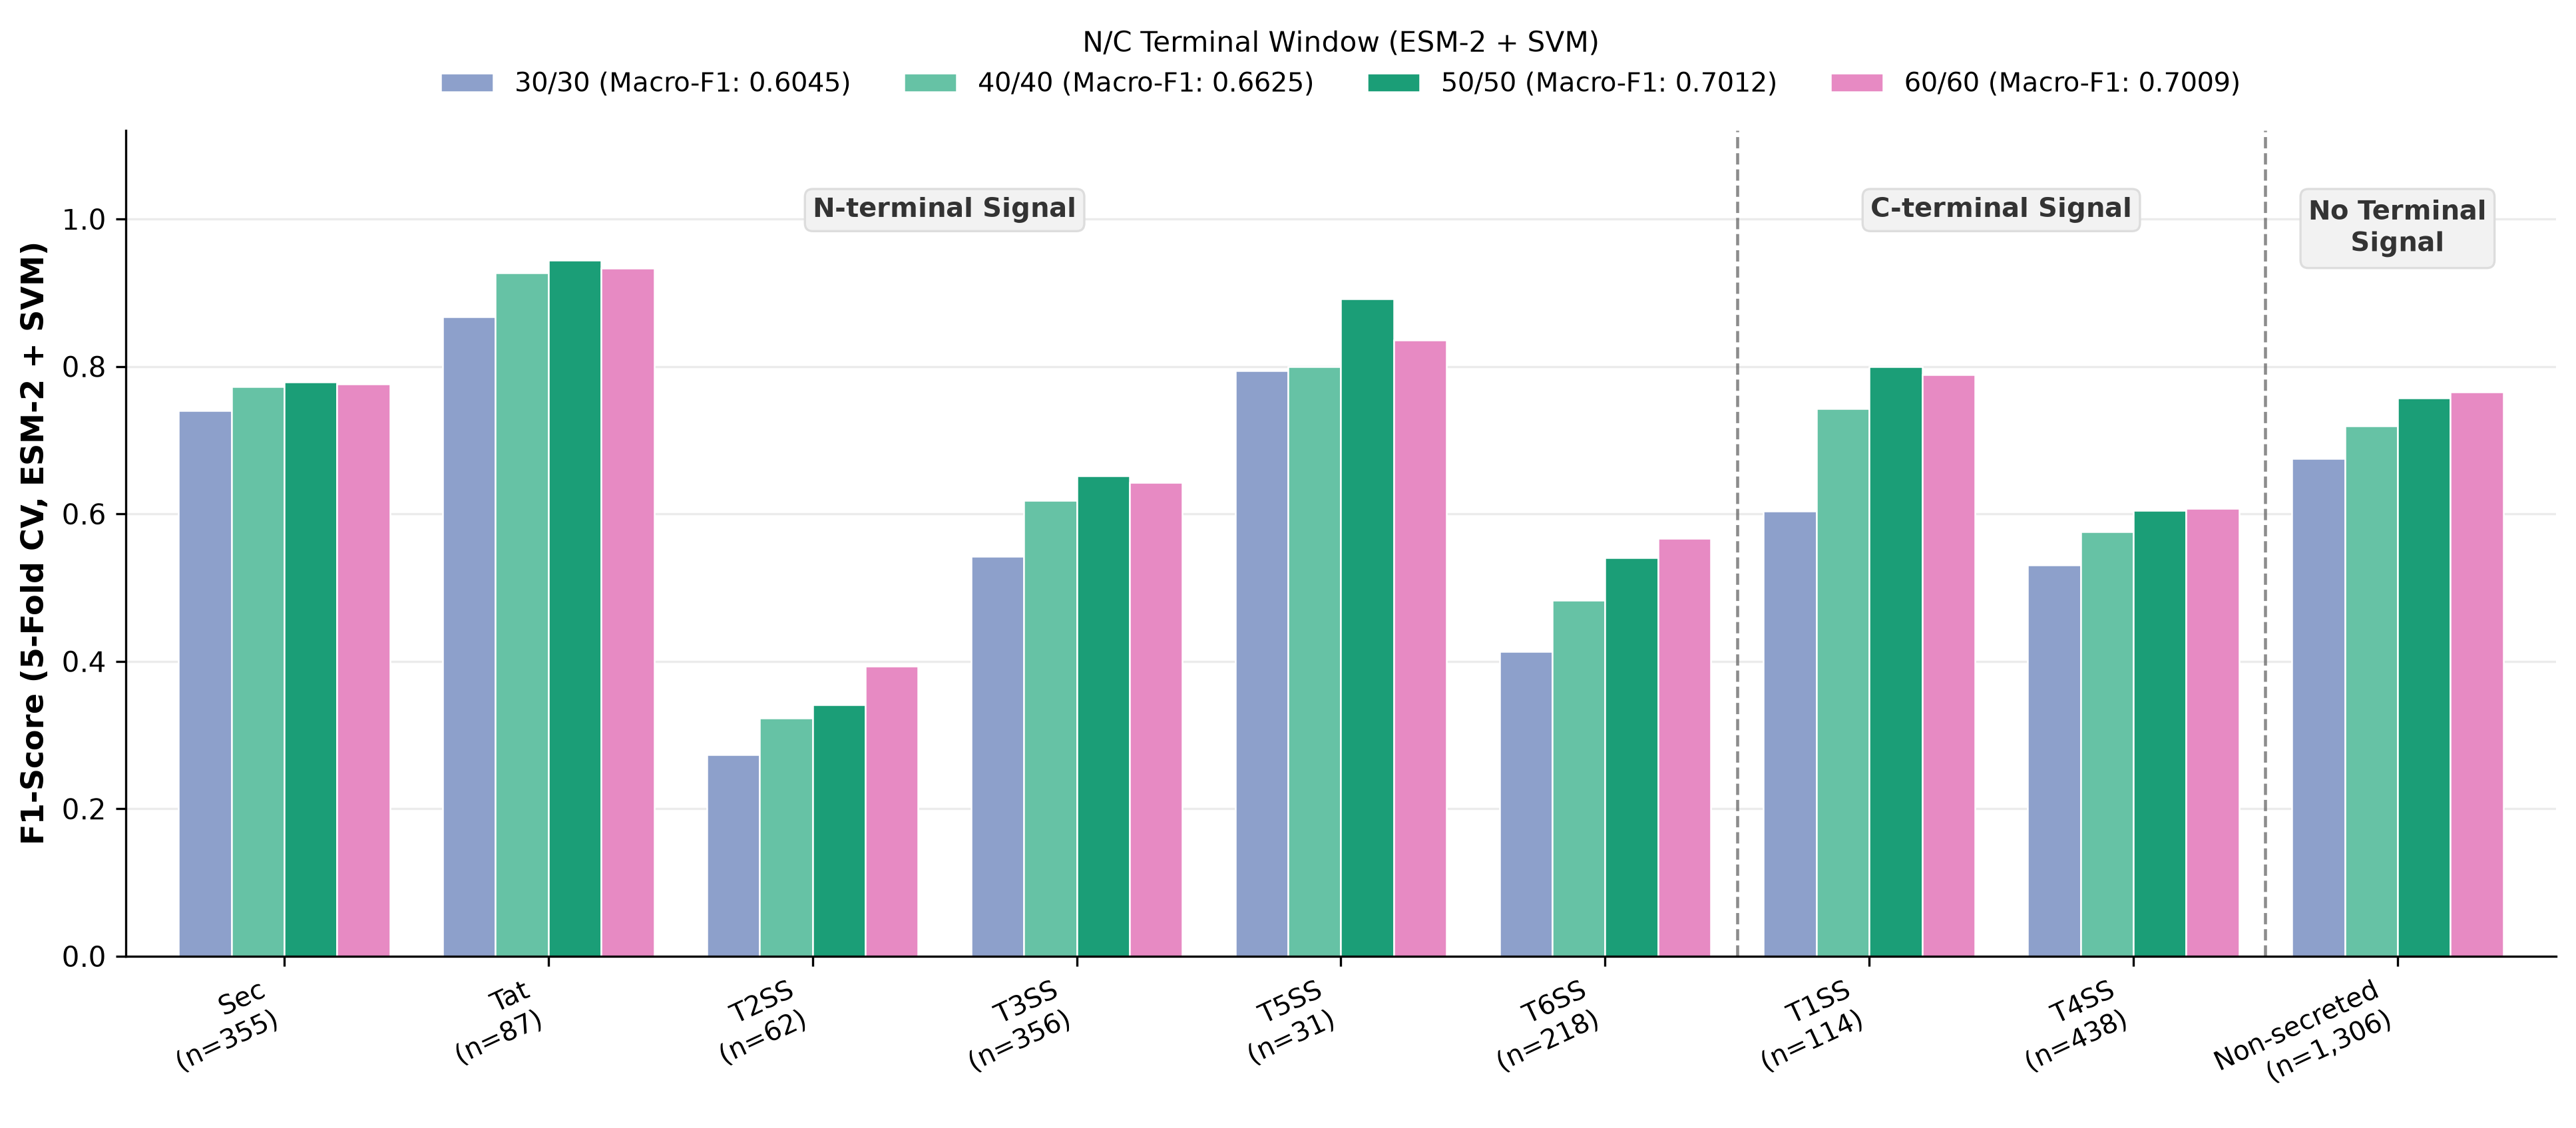

In [70]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Data Setup (Ordered by secretion signal location: N-terminal -> C-terminal -> Non-secreted)
order = ["Sec", "Tat", "T2SS", "T3SS", "T5SS", "T6SS", "T1SS", "T4SS", "Non-secreted"]
support = [355, 87, 62, 356, 31, 218, 114, 438, 1306]
conds = ["30/30", "40/40", "50/50", "60/60"]

# Updated F1-Scores for ESM-2 Embeddings + RBF-SVM (mapped to `order`)
esm2_svm = {
    "30/30": [0.740, 0.867, 0.273, 0.542, 0.794, 0.413, 0.604, 0.531, 0.675],
    "40/40": [0.773, 0.927, 0.323, 0.618, 0.800, 0.483, 0.743, 0.576, 0.719],
    "50/50": [0.779, 0.944, 0.341, 0.652, 0.892, 0.541, 0.800, 0.605, 0.757],
    "60/60": [0.776, 0.933, 0.393, 0.643, 0.836, 0.567, 0.789, 0.607, 0.765],
}

# Exact Macro-F1 values from classification reports
exact_macro_f1 = {
    "30/30": 0.6045,
    "40/40": 0.6625,
    "50/50": 0.7012,
    "60/60": 0.7009,
}

# 2. Biological Group Boundaries:
# Indices 0-5 (6 classes): Sec, Tat, T2SS, T3SS, T5SS, T6SS -> Divider at 5.5, Center at 2.5
# Indices 6-7 (2 classes): T1SS, T4SS                     -> Divider at 7.5, Center at 6.5
# Index   8   (1 class)  : Non-secreted                   -> End at 8.5,     Center at 8.0
groups = [
    (5.5, "N-terminal Signal", 2.5),
    (7.5, "C-terminal Signal", 6.5),
    (None, "No Terminal\nSignal", 8.0),
]

# 3. Dynamic Bar Geometry
n_classes = len(order)
n_conds = len(conds)
x = np.arange(n_classes)
total_cluster_width = 0.80
w = total_cluster_width / n_conds

colors = ["#8da0cb", "#66c2a5", "#1b9e77", "#e78ac3"]

fig, ax = plt.subplots(figsize=(13, 5.8), dpi=300)

for i, c in enumerate(conds):
    offset = (i - (n_conds - 1) / 2) * w
    macro_f1 = exact_macro_f1[c]
    ax.bar(
        x + offset, esm2_svm[c], w,
        label=f"{c} (Macro-F1: {macro_f1:.4f})",
        color=colors[i % len(colors)],
        edgecolor="white", linewidth=0.6
    )

# 4. Draw Dividers & Group Badges
for divider_x, grp_label, text_x in groups:
    if divider_x is not None:
        ax.axvline(divider_x, color="#666666", ls="--", lw=1.1, alpha=0.75)
    ax.text(
        text_x, 1.03, grp_label,
        ha="center", va="top", fontsize=9.5, fontweight="bold", color="#333333",
        bbox=dict(boxstyle="round,pad=0.3", facecolor="#f2f2f2", edgecolor="#dddddd", lw=0.8)
    )

# 5. Formatting & Export
x_labels = [f"{cls}\n(n={n:,})" for cls, n in zip(order, support)]
ax.set_xticks(x)
ax.set_xticklabels(x_labels, rotation=25, ha="right", fontsize=9.5)
ax.set_ylabel("F1-Score (5-Fold CV, ESM-2 + SVM)", fontsize=11, fontweight="bold")
ax.set_ylim(0, 1.12)
ax.set_xlim(-0.6, n_classes - 0.4)

ax.legend(
    title="N/C Terminal Window (ESM-2 + SVM)", ncol=4, loc="upper center",
    bbox_to_anchor=(0.5, 1.15), frameon=False, fontsize=9.5, title_fontsize=10
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(axis="y", alpha=0.25, linestyle="-")
ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig("ESM2_SVM_Window_Comparison.png", dpi=300, bbox_inches="tight")
plt.show()

In [74]:
import pandas as pd

# ==============================================================================
# 1. SET YOUR FULL-LENGTH FASTA FILE PATHS HERE
# ==============================================================================
TRAIN_FASTA = "C:/Users/sumit/OneDrive/Documenten/Thesis/comp-ss/Results/sumit_secretion_prediction/phase0_dataset_prep/Train_Test/train.fasta"  # Replace with your full-length train FASTA path
TEST_FASTA = "C:/Users/sumit/OneDrive/Documenten/Thesis/comp-ss/Results/sumit_secretion_prediction/phase0_dataset_prep/Train_Test/test.fasta"  # Replace with your full-length test FASTA path
MAX_LEN = 1022  # ESM-2 maximum amino acid context limit


# ==============================================================================
# 2. STANDALONE AUDIT FUNCTION (ONLY > 1022 AA SEQUENCES & PROTEIN IDs)
# ==============================================================================
def audit_exceeds_1022(fasta_path, dataset_name="Dataset", max_len=1022):
    records = []
    with open(fasta_path, "r") as f:
        header = None
        seq_chunks = []
        for line in f:
            line = line.strip()
            if not line:
                continue
            if line.startswith(">"):
                if header is not None:
                    records.append((header, "".join(seq_chunks)))
                header = line
                seq_chunks = []
            else:
                seq_chunks.append(line)
        if header is not None:
            records.append((header, "".join(seq_chunks)))

    # Extract protein_id, class label, and length
    rows = []
    for h, seq in records:
        if len(seq) > max_len:
            parts = h[1:].split("|")
            protein_id = parts[0].strip()
            cls = parts[1].strip() if len(parts) > 1 else "Unknown"
            rows.append(
                {"Class": cls, "Protein_ID": protein_id, "Length": len(seq)}
            )

    df_long = pd.DataFrame(rows)

    print("=" * 70)
    print(f"{dataset_name.upper()} : {fasta_path}")
    print(f"Total sequences > {max_len} aa : {len(df_long)}")
    print("=" * 70)

    if df_long.empty:
        print(f"No sequences exceed {max_len} aa.\n")
        return df_long

    # Group by Class: count and list of Protein_IDs
    summary = (
        df_long.groupby("Class")
        .agg(
            Count_Over_1022=("Protein_ID", "count"),
            Protein_IDs=("Protein_ID", lambda ids: ", ".join(ids)),
        )
        .reset_index()
        .sort_values(by="Count_Over_1022", ascending=False)
    )

    for _, row in summary.iterrows():
        print(f"\nClass: {row['Class']}  |  Count > {max_len} aa: {row['Count_Over_1022']}")
        print(f"Protein IDs: {row['Protein_IDs']}")

    print("\n")
    return df_long


# ==============================================================================
# 3. RUN AUDIT
# ==============================================================================
train_long_df = audit_exceeds_1022(
    TRAIN_FASTA, dataset_name="Train Set", max_len=MAX_LEN
)
test_long_df = audit_exceeds_1022(
    TEST_FASTA, dataset_name="Test Set", max_len=MAX_LEN
)

TRAIN SET : C:/Users/sumit/OneDrive/Documenten/Thesis/comp-ss/Results/sumit_secretion_prediction/phase0_dataset_prep/Train_Test/train.fasta
Total sequences > 1022 aa : 155

Class: Unknown  |  Count > 1022 aa: 155
Protein IDs: Non-secreted-678, Non-secreted-1562, Non-secreted-695, Non-secreted-946, Non-secreted-125, Non-secreted-5, Non-secreted-883, Non-secreted-289, Non-secreted-866, Non-secreted-30, Non-secreted-734, Non-secreted-1504, Non-secreted-1387, Non-secreted-42, Non-secreted-778, Non-secreted-945, Non-secreted-493, Non-secreted-878, Sec-171, Sec-173, Sec-420, Sec-456, Sec-96, Sec-324, Sec-375, Sec-404, Sec-329, T1SS-5, T1SS-53, T1SS-129, T1SS-101, T1SS-130, T1SS-142, T1SS-70, T1SS-4, T1SS-68, T1SS-43, T1SS-75, T1SS-111, T1SS-112, T1SS-115, T1SS-22, T1SS-86, T1SS-33, T1SS-97, T1SS-51, T1SS-83, T1SS-34, T1SS-66, T1SS-134, T1SS-120, T1SS-72, T1SS-27, T1SS-59, T1SS-49, T1SS-58, T1SS-126, T1SS-35, T1SS-67, T1SS-99, T1SS-45, T1SS-113, T1SS-60, T1SS-48, T1SS-116, T1SS-117, T1SS-87, 

In [ ]:
import pandas as pd
from pathlib import Path

# Walk up from the working directory until the repository root is found, so the
# cell works whatever folder the notebook was started in.
root = Path.cwd().resolve()
while not (root / "Results").is_dir() and root != root.parent:
    root = root.parent
if not (root / "Results").is_dir():
    raise SystemExit("no 'Results' folder found above %s - open the notebook "
                     "inside the repository" % Path.cwd())
print("repo   :", root)

F = root / "Results/sumit_secretion_prediction/phase1_feature_engineering/features"
FILES = {"AAC": "AAC/AAC_%s.csv",
         "DPC": "DPC/DPC_%s.csv",
         "NCW": "N_C_window/N_C_50_window_esm2_%s.csv"}
EXPECTED = {"train": 2967, "test": 744}

missing = [str(F / (p % s)) for s in EXPECTED for p in FILES.values()
           if not (F / (p % s)).exists()]
if missing:
    print("\nMISSING:")
    for m in missing:
        print("  ", m)
    print("\nwhat is actually under", F)
    for p in sorted(F.rglob("*.csv")):
        print("  ", p.relative_to(F))
    raise SystemExit("\nfix the paths in FILES to match, then re-run")

ids = {}
for split in ["train", "test"]:
    print("\n--- %s ---" % split)
    for name, pat in FILES.items():
        d = pd.read_csv(F / (pat % split))
        ids[(name, split)] = d["Protein_id"]
        print("%-4s %-6d rows x %-4d features   %s"
              % (name, d.shape[0], d.shape[1] - 1, d.columns[1]))
    n = {k[0]: len(v) for k, v in ids.items() if k[1] == split}
    assert len(set(n.values())) == 1, "row counts differ: %s" % n
    assert list(n.values())[0] == EXPECTED[split], \
        "%s has %d rows, expected %d" % (split, list(n.values())[0], EXPECTED[split])
    base = ids[("AAC", split)]
    for name in FILES:
        assert ids[(name, split)].equals(base), "%s/%s id ORDER differs" % (name, split)
    print("ids identical and in the same order across all three blocks")

shared = set(ids[("AAC", "train")]) & set(ids[("AAC", "test")])
print("\nshared ids train/test: %d" % len(shared))
assert not shared, "LEAKAGE: %d proteins in both splits" % len(shared)
print("\nall checks passed - phase 1 output is consistent")


--- train ---


FileNotFoundError: [Errno 2] No such file or directory: 'Results\\sumit_secretion_prediction\\phase1_feature_engineering\\features\\AAC\\AAC_train.csv'